# Лабораторная работа № 1
## ЛП-модель распределения ресурсов: смешение углей для ТЭС

**Индивидуальный вариант:** 14  
**Seed генерации:** 10031  
**Предметная область:** закупка и смешение угля от пяти поставщиков  
**Метод решения:** непрерывное линейное программирование, HiGHS (dual simplex)

**Цель работы:** найти минимальную стоимость закупки смеси заданной массы при соблюдении ограничений по средней зольности, сере и объёмам поставок; независимо проверить решение и провести сценарный и двойственный анализ.

**Основание:** А. А. Кузьмин, «Методы оптимизации. Линейное программирование», комплекс лабораторных работ (2026), ЛР № 1, с. 4–6.

## 1. Индивидуальный вариант и принятые допущения

| Характеристика | Значение |
|---|---|
| Вариант | 14 |
| Seed | 10031 |
| Задача | Смешение углей для ТЭС: минимизация стоимости |
| Поставщики | 5 |
| Три основных требования | Суммарная масса, средняя зольность, среднее содержание серы |
| Дополнительные ограничения | Максимальная отгрузка каждого поставщика |
| Тип переменных | Непрерывные, неотрицательные |

В методичке заданы тематика, масштаб и seed, но **не определены конкретные коэффициенты и алгоритм их генерации**. Поэтому здесь используется документированная синтетическая генерация: фиксированные базовые профили пяти сортов угля и небольшие случайные отклонения. Это собственное учебное допущение, а не исходная таблица преподавателя.

Принятые упрощения: уголь смешивается однородно; зольность и содержание серы усредняются по массе; цены за тонну постоянны; теплота сгорания, влажность, транспортные тарифы и нелинейные эффекты смешения не учитываются; дробные объёмы закупки допустимы.

In [1]:
from pathlib import Path
import json
import platform
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display, Markdown

SEED = 10031
VARIANT = 14
OUTPUT_DIR = Path('lab1_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.grid': True, 'grid.alpha': 0.22})
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
print(f'Вариант {VARIANT}; seed {SEED}; Python {platform.python_version()}; SciPy {scipy.__version__}')

Вариант 14; seed 10031; Python 3.13.5; SciPy 1.17.0


### 1.1. Генерация данных

Правило: для каждого поставщика задаются базовые цена, зольность, сера и максимальный объём. С помощью `numpy.random.default_rng(10031)` генерируются небольшие отклонения. Значения и сам seed сохраняются в JSON **отдельно от математической модели**. При повторном запуске блокнота данные получаются такими же при той же версии NumPy.

Масса требуемой смеси: **1000 т**. Максимальная средняя зольность: **12,3%**, максимальное среднее содержание серы: **1,25%**. Эти пороги приняты как учебные параметры.

In [2]:
rng = np.random.default_rng(SEED)
names = [f'Поставщик {i}' for i in range(1, 6)]
ash_pct = np.round(np.array([6.7, 9.3, 12.5, 16.0, 20.2]) + rng.uniform(-0.5, 0.5, 5), 2)
sulfur_pct = np.round(np.array([0.75, 1.65, 1.05, 0.52, 2.10]) + rng.uniform(-0.08, 0.08, 5), 3)
price = np.array([5300, 4400, 4240, 3770, 3080]) + rng.integers(-90, 91, 5)
capacity = np.array([250, 300, 300, 390, 400]) + rng.integers(-20, 21, 5)

input_data = {
    'variant': VARIANT,
    'seed': SEED,
    'source': 'Учебная синтетическая генерация; диапазоны выбраны для данной ЛР',
    'demand_t': 1000.0,
    'ash_max_pct': 12.3,
    'sulfur_max_pct': 1.25,
    'suppliers': [
        {'name': names[i], 'price_rub_t': int(price[i]), 'ash_pct': float(ash_pct[i]),
         'sulfur_pct': float(sulfur_pct[i]), 'capacity_t': int(capacity[i])}
        for i in range(5)
    ]
}
(OUTPUT_DIR / 'coal_data.json').write_text(json.dumps(input_data, ensure_ascii=False, indent=2), encoding='utf-8')

dataset = json.loads((OUTPUT_DIR / 'coal_data.json').read_text(encoding='utf-8'))
supplier_df = pd.DataFrame(dataset['suppliers']).rename(columns={
    'name': 'Поставщик', 'price_rub_t': 'Цена, ₽/т', 'ash_pct': 'Зольность, %',
    'sulfur_pct': 'Сера, %', 'capacity_t': 'Лимит, т'
})
display(supplier_df)
print(f"Потребность: {dataset['demand_t']:.0f} т; зольность ≤ {dataset['ash_max_pct']}%; сера ≤ {dataset['sulfur_max_pct']}%")
print(f"Совокупный доступный объём: {supplier_df['Лимит, т'].sum():.0f} т")

,Поставщик,"Цена, ₽/т","Зольность, %","Сера, %","Лимит, т"
0,Поставщик 1,5297,6.210,0.678,243
1,Поставщик 2,4319,9.240,1.607,318
2,Поставщик 3,4225,12.880,1.082,304
3,Поставщик 4,3854,16.170,0.560,405
4,Поставщик 5,3137,20.210,2.152,382


Потребность: 1000 т; зольность ≤ 12.3%; сера ≤ 1.25%
Совокупный доступный объём: 1652 т


### 1.2. Исходные данные: цена и качество

Графики показывают компромисс между стоимостью и качеством сырья. Самый дешёвый сорт не обязан быть допустимым в качестве всей смеси.

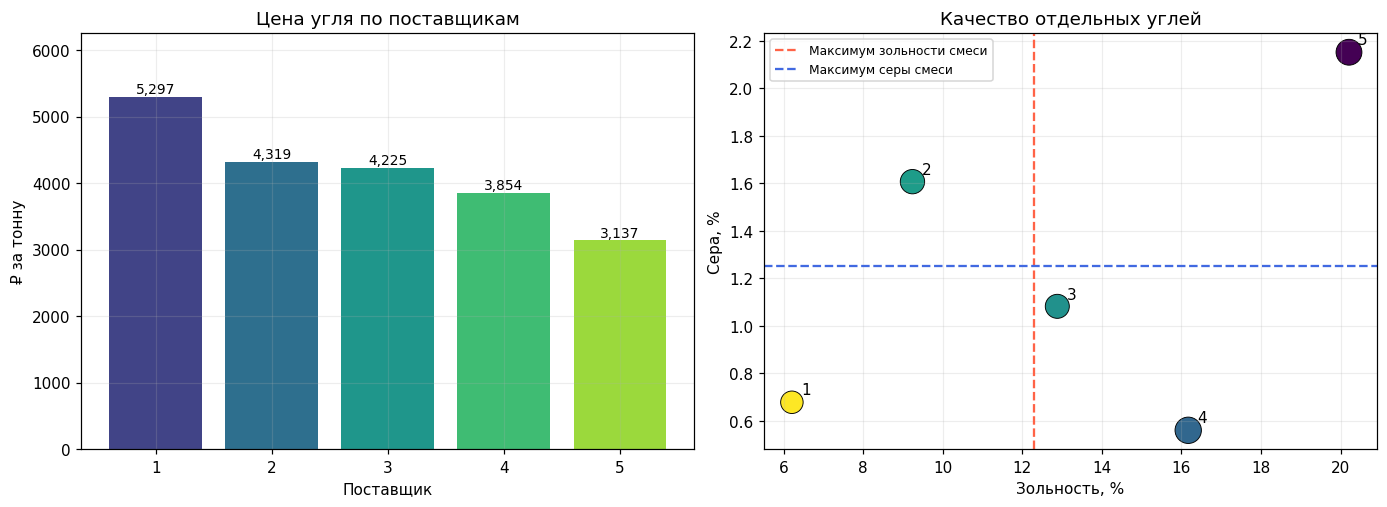

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5), constrained_layout=True)
idx = np.arange(1, 6)
ax[0].bar(idx, supplier_df['Цена, ₽/т'], color=plt.cm.viridis(np.linspace(0.2, 0.85, 5)))
ax[0].set(title='Цена угля по поставщикам', xlabel='Поставщик', ylabel='₽ за тонну', xticks=idx)
ax[0].set_ylim(0, max(price) * 1.18)
for i, value in enumerate(price):
    ax[0].text(i + 1, value + 55, f'{value:,.0f}', ha='center', fontsize=9)
ax[1].scatter(ash_pct, sulfur_pct, s=95 + 0.5 * capacity, c=price, cmap='viridis', edgecolors='black', linewidths=0.6)
for i in range(5):
    ax[1].annotate(str(i + 1), (ash_pct[i], sulfur_pct[i]), xytext=(6, 5), textcoords='offset points', fontsize=10)
ax[1].axvline(dataset['ash_max_pct'], ls='--', color='tomato', label='Максимум зольности смеси')
ax[1].axhline(dataset['sulfur_max_pct'], ls='--', color='royalblue', label='Максимум серы смеси')
ax[1].set(title='Качество отдельных углей', xlabel='Зольность, %', ylabel='Сера, %')
ax[1].legend(fontsize=8, loc='upper left')
fig.savefig(OUTPUT_DIR / '01_suppliers.png', bbox_inches='tight')
plt.show()

## 2. Математическая модель

Пусть $I=\{1,2,3,4,5\}$ — множество поставщиков. Для поставщика $i$ определены параметры:

- $c_i$ — цена закупки, ₽/т;
- $a_i$ — зольность, %;
- $s_i$ — содержание серы, %;
- $u_i$ — максимальный доступный объём, т.

Дополнительные параметры: $D=1000$ т — потребность ТЭС; $A_{\max}=12{,}3\%$ и $S_{\max}=1{,}25\%$ — допустимые средние показатели качества.

**Переменная решения:** $x_i$ — масса угля, закупаемого у поставщика $i$, т.

**Целевая функция:**

$$\min_{x} C(x)=\sum_{i=1}^{5}c_i x_i.$$

**Ограничения:**

$$\begin{aligned}
\sum_{i=1}^{5}x_i &= D &&\text{(баланс массы)},\\
\sum_{i=1}^{5}a_i x_i &\le A_{\max}D &&\text{(зольность)},\\
\sum_{i=1}^{5}s_i x_i &\le S_{\max}D &&\text{(сера)},\\
0\le x_i &\le u_i,\quad i=1,\ldots,5 &&\text{(отгрузка)}.
\end{aligned}$$

Зольность смеси равна $\overline a=\sum_i a_ix_i/D$, содержание серы — $\overline s=\sum_i s_ix_i/D$. Поскольку $D$ фиксировано, условия на средние величины линейны. В строках матрицы используются единицы «процентный пункт × тонна».

**Матричная форма:** $\min c^\mathsf{T}x$ при $A_{ub}x\le b_{ub}$, $A_{eq}x=b_{eq}$, $0\le x\le u$, где

$$A_{ub}=\begin{pmatrix}a_1&\cdots&a_5\\s_1&\cdots&s_5\end{pmatrix},\qquad
b_{ub}=\begin{pmatrix}A_{\max}D\\S_{\max}D\end{pmatrix},\qquad
A_{eq}=\begin{pmatrix}1&1&1&1&1\end{pmatrix},\qquad b_{eq}=D.$$

## 3. Оптимизация базовой модели

Решатель — открытый **HiGHS** через `scipy.optimize.linprog`, метод `highs-ds` (двойственный симплекс), предварительная обработка `presolve=True`. Для каждого расчёта фиксируются статус, число итераций и значение функции. Статус `optimal` означает, что найден оптимум непрерывной ЛП при заданных численных допусках.

In [4]:
prices = np.array([s['price_rub_t'] for s in dataset['suppliers']], dtype=float)
ashes = np.array([s['ash_pct'] for s in dataset['suppliers']], dtype=float)
sulfurs = np.array([s['sulfur_pct'] for s in dataset['suppliers']], dtype=float)
limits = np.array([s['capacity_t'] for s in dataset['suppliers']], dtype=float)
D = float(dataset['demand_t'])
A_MAX = float(dataset['ash_max_pct'])
S_MAX = float(dataset['sulfur_max_pct'])


def solve_mix(caps=None, ash_limit=None, sulfur_limit=None):
    cap = np.asarray(limits if caps is None else caps, dtype=float)
    a_limit = A_MAX if ash_limit is None else float(ash_limit)
    s_limit = S_MAX if sulfur_limit is None else float(sulfur_limit)
    return linprog(
        c=prices,
        A_ub=np.vstack((ashes, sulfurs)),
        b_ub=np.array([a_limit * D, s_limit * D]),
        A_eq=np.ones((1, len(prices))),
        b_eq=np.array([D]),
        bounds=list(zip(np.zeros(len(cap)), cap)),
        method='highs-ds',
        options={'presolve': True, 'primal_feasibility_tolerance': 1e-9,
                 'dual_feasibility_tolerance': 1e-9}
    )


status_names = {0: 'optimal', 1: 'time_limit / iteration_limit', 2: 'infeasible',
                3: 'unbounded', 4: 'solver_error'}
base = solve_mix()
print('Статус:', status_names.get(base.status, str(base.status)))
print('Сообщение:', base.message)
print('Итераций:', base.nit)
if base.success:
    print(f'Минимальная стоимость: {base.fun:,.2f} ₽')

Статус: optimal
Сообщение: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Итераций: 4
Минимальная стоимость: 4,195,862.48 ₽


In [5]:
if not base.success:
    raise RuntimeError(f'Базовая модель не решена: {base.message}')

base_solution = pd.DataFrame({
    'Поставщик': names,
    'Закупка, т': base.x,
    'Доступно, т': limits,
    'Использование лимита, %': base.x / limits * 100,
    'Цена, ₽/т': prices,
    'Затраты, ₽': base.x * prices
})
base_solution.to_csv(OUTPUT_DIR / 'solution.csv', index=False, encoding='utf-8-sig')
display(base_solution)

ash_base = float(ashes @ base.x / D)
sulfur_base = float(sulfurs @ base.x / D)
print(f'Итоговая смесь: {D:.0f} т; стоимость {base.fun:,.2f} ₽; {base.fun / D:,.2f} ₽/т')
print(f'Средняя зольность: {ash_base:.6f}% (лимит {A_MAX:.2f}%)')
print(f'Средняя сера: {sulfur_base:.6f}% (лимит {S_MAX:.2f}%)')
print('Активные верхние границы:', ', '.join(names[i] for i in range(5) if abs(base.x[i] - limits[i]) < 1e-6) or 'нет')
print('Нулевые закупки:', ', '.join(names[i] for i in range(5) if base.x[i] < 1e-7) or 'нет')

,Поставщик,"Закупка, т","Доступно, т","Использование лимита, %","Цена, ₽/т","Затраты, ₽"
0,Поставщик 1,113.992,243.000,46.910,"5,297.000","603,813.660"
1,Поставщик 2,318.000,318.000,100.000,"4,319.000","1,373,442.000"
2,Поставщик 3,304.000,304.000,100.000,"4,225.000","1,284,400.000"
3,Поставщик 4,147.856,405.000,36.508,"3,854.000","569,836.023"
4,Поставщик 5,116.153,382.000,30.406,"3,137.000","364,370.802"


Итоговая смесь: 1000 т; стоимость 4,195,862.48 ₽; 4,195.86 ₽/т
Средняя зольность: 12.300000% (лимит 12.30%)
Средняя сера: 1.250000% (лимит 1.25%)
Активные верхние границы: Поставщик 2, Поставщик 3
Нулевые закупки: нет


### 3.1. Структура оптимальной смеси

На диаграммах показано, сколько тонн нужно закупить у каждого поставщика и какая часть общих расходов приходится на него.

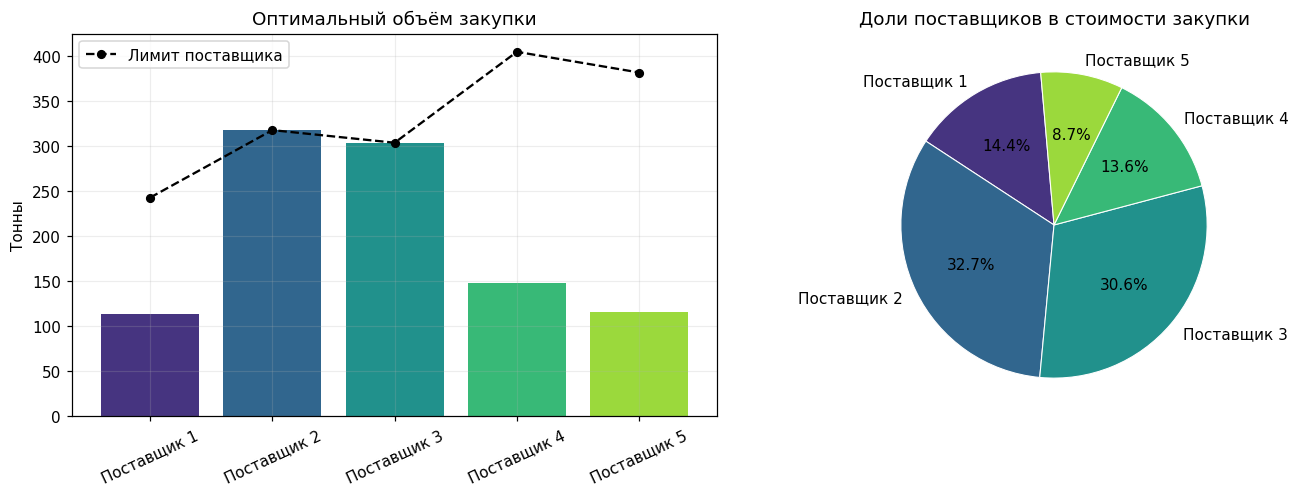

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4), constrained_layout=True)
colors = plt.cm.viridis(np.linspace(0.15, 0.85, 5))
ax[0].bar(names, base.x, color=colors)
ax[0].plot(names, limits, 'ko--', label='Лимит поставщика', markersize=5)
ax[0].set(title='Оптимальный объём закупки', ylabel='Тонны')
ax[0].tick_params(axis='x', rotation=25)
ax[0].legend()
ax[1].pie(base.x * prices, labels=names, autopct='%1.1f%%', startangle=95, colors=colors,
          wedgeprops={'linewidth': 0.7, 'edgecolor': 'white'})
ax[1].set_title('Доли поставщиков в стоимости закупки')
fig.savefig(OUTPUT_DIR / '02_optimal_mix.png', bbox_inches='tight')
plt.show()

## 4. Независимая проверка результата

Проверка выполняется отдельными операциями NumPy по сохранённому JSON и найденному вектору. Здесь **не используются** объект ограничений и рассчитанная солвером стоимость. Допустимое абсолютное нарушение каждого ограничения — не более $10^{-7}$. Это подтверждает допустимость, но математическая оптимальность обеспечивается завершением решателя с соответствующим статусом.

In [7]:
def independent_check(x, source, caps=None, ash_limit=None, sulfur_limit=None):
    suppliers = source['suppliers']
    x = np.asarray(x, dtype=float)
    c = np.array([v['price_rub_t'] for v in suppliers], dtype=float)
    a = np.array([v['ash_pct'] for v in suppliers], dtype=float)
    s = np.array([v['sulfur_pct'] for v in suppliers], dtype=float)
    cap = np.array([v['capacity_t'] for v in suppliers], dtype=float) if caps is None else np.asarray(caps, dtype=float)
    mass = float(source['demand_t'])
    ash_lim = float(source['ash_max_pct']) if ash_limit is None else float(ash_limit)
    sulfur_lim = float(source['sulfur_max_pct']) if sulfur_limit is None else float(sulfur_limit)
    residuals = {
        'Баланс массы, т': abs(np.sum(x) - mass),
        'Превышение зольности, %·т': max(float(a @ x - ash_lim * mass), 0.0),
        'Превышение серы, %·т': max(float(s @ x - sulfur_lim * mass), 0.0),
        'Нарушение x ≥ 0, т': float(np.max(np.maximum(-x, 0.0))),
        'Превышение поставок, т': float(np.max(np.maximum(x - cap, 0.0)))
    }
    return {
        'остатки': residuals,
        'максимальное_нарушение': max(residuals.values()),
        'стоимость_независимая': float(c @ x),
        'средняя_зольность': float(a @ x / mass),
        'средняя_сера': float(s @ x / mass),
        'допустимо': max(residuals.values()) <= 1e-7
    }


check = independent_check(base.x, dataset)
check_df = pd.DataFrame([{'Проверка': key, 'Нарушение': value} for key, value in check['остатки'].items()])
display(check_df)
print('Допустимость подтверждена:', check['допустимо'])
print(f'Независимая стоимость: {check["стоимость_независимая"]:,.6f} ₽')
print(f'Разность с результатом HiGHS: {abs(check["стоимость_независимая"] - base.fun):.9f} ₽')
assert check['допустимо']
assert np.isclose(check['стоимость_независимая'], base.fun, rtol=1e-12, atol=1e-7)

,Проверка,Нарушение
0,"Баланс массы, т",0.000
1,"Превышение зольности, %·т",0.000
2,"Превышение серы, %·т",0.000
3,"Нарушение x ≥ 0, т",0.000
4,"Превышение поставок, т",0.000


Допустимость подтверждена: True
Независимая стоимость: 4,195,862.484924 ₽
Разность с результатом HiGHS: 0.000000000 ₽


## 5. Активные ограничения и теневые цены

Ограничение **активно**, если достигнуто равенство. Для качества это означает полное использование допустимого уровня зольности либо серы; для поставщика — закупку всего доступного объёма.

В результате SciPy `marginals` выражают изменение минимальной стоимости при увеличении соответствующей правой части на единицу. Для ограничений типа «≤» и верхних границ в задаче минимизации они обычно неположительны. Их противоположная величина показывает экономический **выигрыш от ослабления** лимита.

In [8]:
quality_slack = np.array([A_MAX * D - ashes @ base.x, S_MAX * D - sulfurs @ base.x])
upper_slack = limits - base.x
q_shadow = np.asarray(base.ineqlin.marginals, dtype=float)
u_shadow = np.asarray(base.upper.marginals, dtype=float)

economic_table = pd.DataFrame({
    'Ограничение': ['Зольность смеси', 'Сера смеси'] + [f'Лимит: {v}' for v in names],
    'Остаток': np.r_[quality_slack, upper_slack],
    'Активно': np.abs(np.r_[quality_slack, upper_slack]) < 1e-6,
    'Маржинальная оценка': np.r_[q_shadow, u_shadow],
    'Выгода от +1 единицы RHS, ₽': -np.r_[q_shadow, u_shadow]
})
display(economic_table)
print('Единицы: качество — ₽/(%·т), лимиты поставщиков — ₽/т дополнительной поставки.')
print(f'Увеличение допустимой зольности на 0,01 п.п.: локальный прогноз {q_shadow[0] * D * 0.01:,.2f} ₽')
print(f'Увеличение допустимой серы на 0,01 п.п.: локальный прогноз {q_shadow[1] * D * 0.01:,.2f} ₽')

,Ограничение,Остаток,Активно,Маржинальная оценка,"Выгода от +1 единицы RHS, ₽"
0,Зольность смеси,0.000,True,-145.831,145.831
1,Сера смеси,0.000,True,-80.303,80.303
2,Лимит: Поставщик 1,129.008,False,0.000,-0.000
3,Лимит: Поставщик 2,0.000,True,-461.530,461.530
4,Лимит: Поставщик 3,0.000,True,-66.865,66.865
5,Лимит: Поставщик 4,257.144,False,0.000,-0.000
6,Лимит: Поставщик 5,265.847,False,0.000,-0.000


Единицы: качество — ₽/(%·т), лимиты поставщиков — ₽/т дополнительной поставки.
Увеличение допустимой зольности на 0,01 п.п.: локальный прогноз -1,458.31 ₽
Увеличение допустимой серы на 0,01 п.п.: локальный прогноз -803.03 ₽


### 5.1. Проверка двойственных оценок и оптимальности

Для минимума при ограничениях $A_{ub}x\le b_{ub}$ оценки правых частей $m_{ub}$ неположительны. При наличии равенства и двусторонних границ выполняется условие стационарности:

$$c-A_{eq}^{\mathsf T}m_{eq}-A_{ub}^{\mathsf T}m_{ub}-m_{lower}-m_{upper}=0.$$

Дополняющая нежёсткость означает, что ненулевая оценка может соответствовать лишь активному ограничению. Проверим стационарность, допустимость знаков и произведения оценок на остатки.

In [9]:
A_ub = np.vstack((ashes, sulfurs))
A_eq = np.ones((1, 5))
m_eq = np.atleast_1d(base.eqlin.marginals)
m_lb = np.asarray(base.lower.marginals)
m_ub = np.asarray(base.upper.marginals)
m_ineq = np.asarray(base.ineqlin.marginals)
stationarity = prices - A_eq.T @ m_eq - A_ub.T @ m_ineq - m_lb - m_ub
kkt = {
    'Макс. невязка стационарности': float(np.max(abs(stationarity))),
    'Макс. произведение оценка × остаток (качество)': float(np.max(abs(m_ineq * quality_slack))),
    'Макс. произведение оценка × остаток (верхние границы)': float(np.max(abs(m_ub * upper_slack))),
    'Макс. произведение оценка × остаток (нижние границы)': float(np.max(abs(m_lb * base.x)))
}
display(pd.DataFrame([{'Проверка': k, 'Значение': v} for k, v in kkt.items()]))
print('marginals качества ≤ 0:', np.all(m_ineq <= 1e-8))
print('marginals верхних границ ≤ 0:', np.all(m_ub <= 1e-8))
print('marginals нижних границ ≥ 0:', np.all(m_lb >= -1e-8))
assert max(kkt.values()) < 1e-6

,Проверка,Значение
0,Макс. невязка стационарности,0.000
1,Макс. произведение оценка × остаток (качество),0.000
2,Макс. произведение оценка × остаток (верхние г...,0.000
3,Макс. произведение оценка × остаток (нижние гр...,0.000


marginals качества ≤ 0: True
marginals верхних границ ≤ 0: True
marginals нижних границ ≥ 0: True


### 5.2. Проверка теневых цен небольшими изменениями

Сравним прогноз на основе двойственных оценок и фактический результат повторного решения. Для активных ограничений рассматриваем малые положительные изменения правых частей, чтобы локальная линейная оценка была применима.

In [10]:
ash_step = 0.01
sulfur_step = 0.01
cap_step = 5.0
cap_candidates = np.where(np.abs(upper_slack) < 1e-7)[0]
cap_idx = int(cap_candidates[0]) if len(cap_candidates) else int(np.argmin(upper_slack))
caps_more = limits.copy()
caps_more[cap_idx] += cap_step

local_tests = [
    ('Зольность: +0,01 п.п.', base.fun + q_shadow[0] * D * ash_step,
     solve_mix(ash_limit=A_MAX + ash_step)),
    ('Сера: +0,01 п.п.', base.fun + q_shadow[1] * D * sulfur_step,
     solve_mix(sulfur_limit=S_MAX + sulfur_step)),
    (f'{names[cap_idx]}: +5 т лимита', base.fun + u_shadow[cap_idx] * cap_step,
     solve_mix(caps=caps_more))
]
local_rows = []
for title, prediction, result in local_tests:
    local_rows.append({'Изменение': title, 'Прогноз стоимости, ₽': prediction,
                       'Фактическая стоимость, ₽': result.fun if result.success else np.nan,
                       'Разница прогноза, ₽': (result.fun - prediction) if result.success else np.nan})
display(pd.DataFrame(local_rows))

,Изменение,"Прогноз стоимости, ₽","Фактическая стоимость, ₽","Разница прогноза, ₽"
0,"Зольность: +0,01 п.п.","4,194,404.176","4,194,404.176",0.000
1,"Сера: +0,01 п.п.","4,195,059.450","4,195,059.450",0.000
2,Поставщик 2: +5 т лимита,"4,193,554.833","4,193,554.833",0.000


## 6. Сценарный анализ

**Базовый:** исходные цены, доступные объёмы и нормативы.

**Дефицитный:** поставщик № 2 сокращает поставки на **20%**.

**Стрессовый:** поставщики № 2 и № 3 одновременно сокращают лимиты на **20%**, а требования к смеси ужесточаются до **10,5% зольности** и **0,9% серы**.

**Дополнительный жёсткий допустимый:** те же два сокращения поставок по 20%, но нормативы **11,3%** и **1,0%**. Этот сценарий нужен для количественного сравнения, даже если основной стрессовый оказался несовместным.

In [11]:
cap_deficit = limits.copy()
cap_deficit[1] *= 0.8
cap_stress = limits.copy()
cap_stress[1] *= 0.8
cap_stress[2] *= 0.8

scenario_specs = [
    {'Название': 'Базовый', 'caps': limits, 'ash': A_MAX, 'sulfur': S_MAX},
    {'Название': 'Дефицитный', 'caps': cap_deficit, 'ash': A_MAX, 'sulfur': S_MAX},
    {'Название': 'Стрессовый', 'caps': cap_stress, 'ash': 10.5, 'sulfur': 0.9},
    {'Название': 'Жёсткий допустимый', 'caps': cap_stress, 'ash': 11.3, 'sulfur': 1.0}
]
scenario_results = {}
scenario_rows = []
scenario_check_rows = []
for spec in scenario_specs:
    name = spec['Название']
    result = solve_mix(caps=spec['caps'], ash_limit=spec['ash'], sulfur_limit=spec['sulfur'])
    scenario_results[name] = result
    verified = independent_check(result.x, dataset, caps=spec['caps'],
                                 ash_limit=spec['ash'], sulfur_limit=spec['sulfur']) if result.success else None
    scenario_rows.append({
        'Сценарий': name,
        'Статус': status_names.get(result.status, str(result.status)),
        'Стоимость, ₽': result.fun if result.success else np.nan,
        'Изменение, ₽': result.fun - base.fun if result.success else np.nan,
        'Зольность, %': verified['средняя_зольность'] if verified else np.nan,
        'Сера, %': verified['средняя_сера'] if verified else np.nan,
        'Итерации HiGHS': result.nit
    })
    if result.success:
        scenario_check_rows.append({'Сценарий': name, 'Проверка допустимости': verified['допустимо'],
                                    'Максимальная невязка': verified['максимальное_нарушение'],
                                    'Расхождение стоимости, ₽': abs(verified['стоимость_независимая'] - result.fun)})
scenario_df = pd.DataFrame(scenario_rows)
scenario_df.to_csv(OUTPUT_DIR / 'scenarios.csv', index=False, encoding='utf-8-sig')
display(scenario_df)
display(pd.DataFrame(scenario_check_rows))
assert all(row['Проверка допустимости'] for row in scenario_check_rows)

,Сценарий,Статус,"Стоимость, ₽","Изменение, ₽","Зольность, %","Сера, %",Итерации HiGHS
0,Базовый,optimal,"4,195,862.485",0.000,12.300,1.250,4
1,Дефицитный,optimal,"4,225,215.820","29,353.335",12.300,1.250,4
2,Стрессовый,infeasible,NaN,NaN,NaN,NaN,3
3,Жёсткий допустимый,optimal,"4,395,188.003","199,325.518",11.300,1.000,4


,Сценарий,Проверка допустимости,Максимальная невязка,"Расхождение стоимости, ₽"
0,Базовый,True,0.000,0.000
1,Дефицитный,True,0.000,0.000
2,Жёсткий допустимый,True,0.000,0.000


### 6.1. Изменение плана закупок

Сравниваются только допустимые сценарии. Для несовместного стрессового случая оптимального плана не существует.

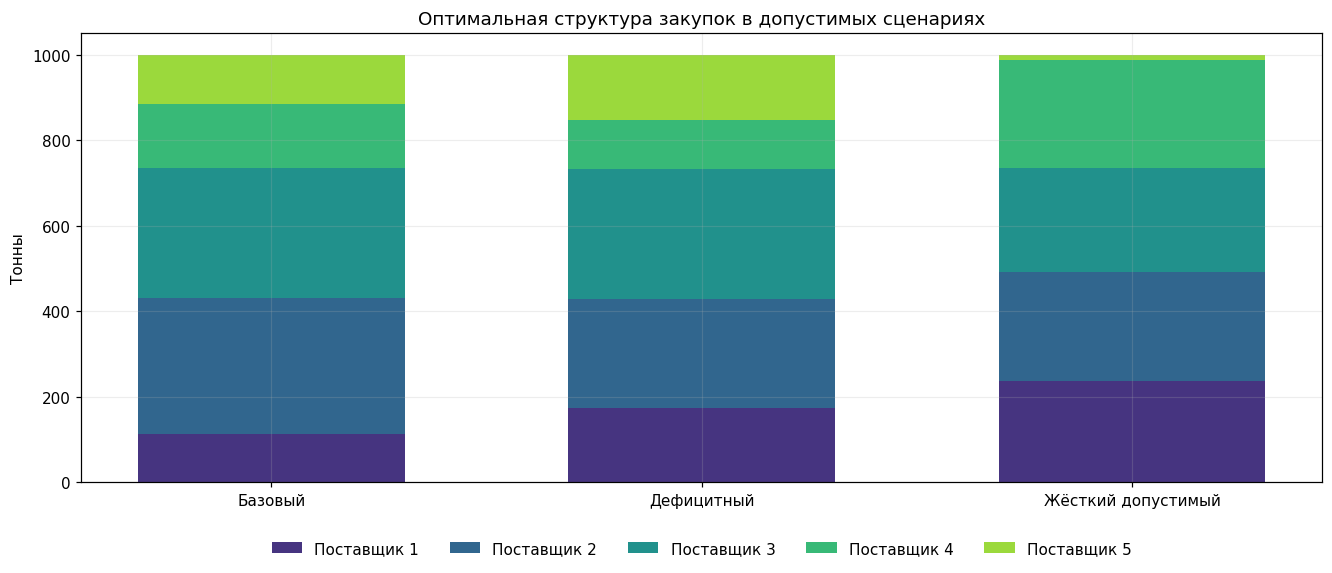

,Поставщик,Базовый,Дефицитный,Жёсткий допустимый
0,Поставщик 1,113.992,173.423,236.404
1,Поставщик 2,318.000,254.400,254.400
2,Поставщик 3,304.000,304.000,243.200
3,Поставщик 4,147.856,114.602,254.189
4,Поставщик 5,116.153,153.575,11.807


In [12]:
feasible_names = [spec['Название'] for spec in scenario_specs if scenario_results[spec['Название']].success]
xmat = np.vstack([scenario_results[name].x for name in feasible_names])
positions = np.arange(len(feasible_names))
fig, ax = plt.subplots(figsize=(12, 5.1), constrained_layout=True)
bottom = np.zeros(len(feasible_names))
for i, nm in enumerate(names):
    ax.bar(positions, xmat[:, i], bottom=bottom, label=nm, color=colors[i], width=0.62)
    bottom += xmat[:, i]
ax.set(xticks=positions, xticklabels=feasible_names, ylabel='Тонны',
       title='Оптимальная структура закупок в допустимых сценариях')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.10), frameon=False)
fig.savefig(OUTPUT_DIR / '03_scenario_composition.png', bbox_inches='tight')
plt.show()

display(pd.DataFrame({'Поставщик': names, **{name: scenario_results[name].x for name in feasible_names}}))

### 6.2. Стоимость и качество в сценариях

Изменение стоимости отсчитывается от базовой модели; нарушение нормативов недопустимо. Сценарий со статусом `infeasible` на диаграмму стоимостей не наносится, потому что конечной оптимальной стоимости для него нет.

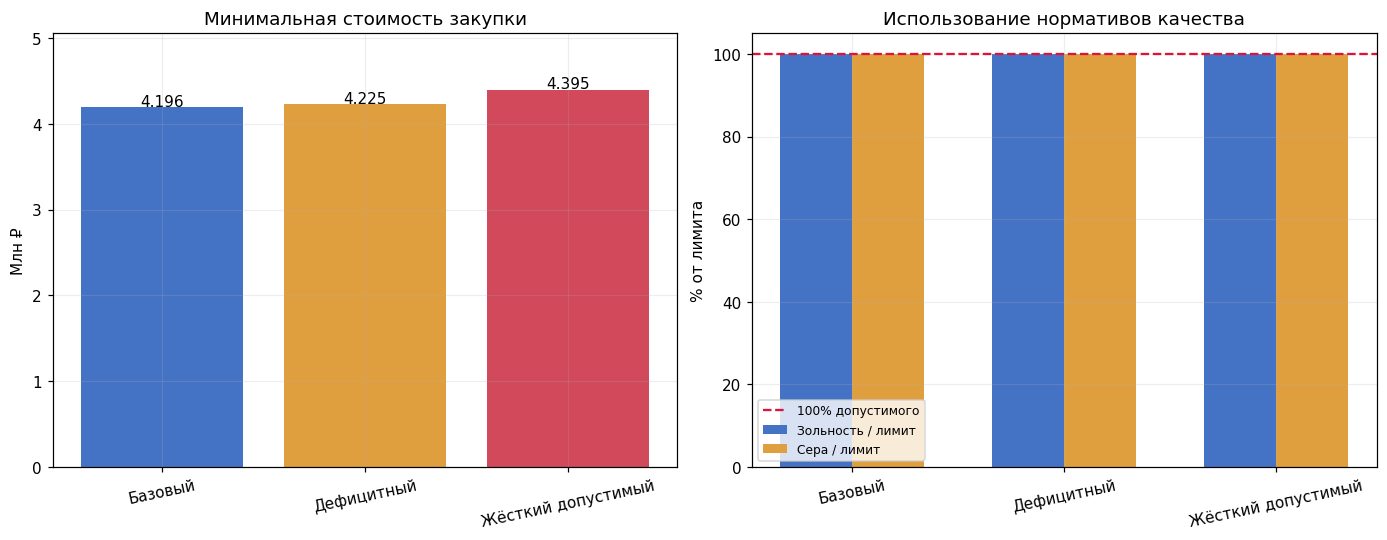

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)
vals = [scenario_results[n].fun / 1e6 for n in feasible_names]
bar = ax[0].bar(np.arange(len(feasible_names)), vals, color=['#4472c4', '#e09f3e', '#d1495b'])
ax[0].set(xticks=np.arange(len(feasible_names)), xticklabels=feasible_names,
          title='Минимальная стоимость закупки', ylabel='Млн ₽')
ax[0].tick_params(axis='x', rotation=12)
for b, v in zip(bar, vals):
    ax[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f'{v:.3f}', ha='center')
ax[0].set_ylim(0, max(vals) * 1.15)
positions = np.arange(len(feasible_names))
width = 0.34
for i, name in enumerate(feasible_names):
    r = scenario_results[name]
    ax[1].bar(i - width/2, (ashes @ r.x / D) / scenario_specs[[s['Название'] for s in scenario_specs].index(name)]['ash'] * 100,
              width, color='#4472c4', label='Зольность / лимит' if i == 0 else None)
    ax[1].bar(i + width/2, (sulfurs @ r.x / D) / scenario_specs[[s['Название'] for s in scenario_specs].index(name)]['sulfur'] * 100,
              width, color='#e09f3e', label='Сера / лимит' if i == 0 else None)
ax[1].axhline(100, color='crimson', linestyle='--', label='100% допустимого')
ax[1].set(xticks=positions, xticklabels=feasible_names, title='Использование нормативов качества', ylabel='% от лимита')
ax[1].tick_params(axis='x', rotation=12)
ax[1].legend(fontsize=8)
fig.savefig(OUTPUT_DIR / '04_scenario_comparison.png', bbox_inches='tight')
plt.show()

### 6.3. Почему стрессовый сценарий несовместен

Одного сообщения `infeasible` недостаточно. Чтобы предъявить численное доказательство конфликта, решим вспомогательную ЛП:

$$\min \sum_i a_i x_i \quad\text{при}\quad \sum_i x_i=1000,\; \sum_i s_ix_i\le 0{,}9\cdot1000,\;0\le x_i\le u_i^{stress}.$$

То есть найдём **минимальную физически достижимую среднюю зольность**, даже не требуя изначально зольность $\le10{,}5\%$. Если полученный минимум выше $10{,}5\%$, одновременное выполнение заданных условий невозможно. Это конкретное обоснование несовместности ограничений на качество, баланс массы и доступные поставки.

In [14]:
stress = scenario_results['Стрессовый']
assert stress.status == 2
ash_aux = linprog(
    c=ashes,
    A_ub=np.array([sulfurs]),
    b_ub=np.array([0.9 * D]),
    A_eq=np.ones((1, 5)),
    b_eq=np.array([D]),
    bounds=list(zip(np.zeros(5), cap_stress)),
    method='highs-ds'
)
if not ash_aux.success:
    print('Даже баланс массы и требование по сере без ограничения зольности несовместны.')
else:
    min_ash_achievable = float(ashes @ ash_aux.x / D)
    print(f'При сере ≤ 0,9% и сокращённых поставках минимальная зольность = {min_ash_achievable:.6f}%')
    print('Стрессовый лимит зольности = 10,500000%')
    print(f'Неустранимое превышение по зольности = {min_ash_achievable - 10.5:.6f} процентного пункта')
    print('Следовательно, одновременно выполнить все ограничения стрессового сценария нельзя.')
    display(pd.DataFrame({'Поставщик': names, 'Минимизация зольности, т': ash_aux.x,
                          'Доступно при стрессе, т': cap_stress}))
    assert min_ash_achievable > 10.5

При сере ≤ 0,9% и сокращённых поставках минимальная зольность = 11.707071%
Стрессовый лимит зольности = 10,500000%
Неустранимое превышение по зольности = 1.207071 процентного пункта
Следовательно, одновременно выполнить все ограничения стрессового сценария нельзя.


,Поставщик,"Минимизация зольности, т","Доступно при стрессе, т"
0,Поставщик 1,243.000,243.000
1,Поставщик 2,243.013,254.400
2,Поставщик 3,108.987,243.200
3,Поставщик 4,405.000,405.000
4,Поставщик 5,0.000,382.000


## 7. Анализ чувствительности по качеству смеси

При фиксированных ценах и поставках меняется максимально допустимая зольность. Это показывает, что более строгий экологический норматив обычно увеличивает минимальную стоимость. Пунктирная линия — локальный прогноз из теневой цены базовой задачи; вне области устойчивости оптимального базиса прогноз может перестать быть точным.

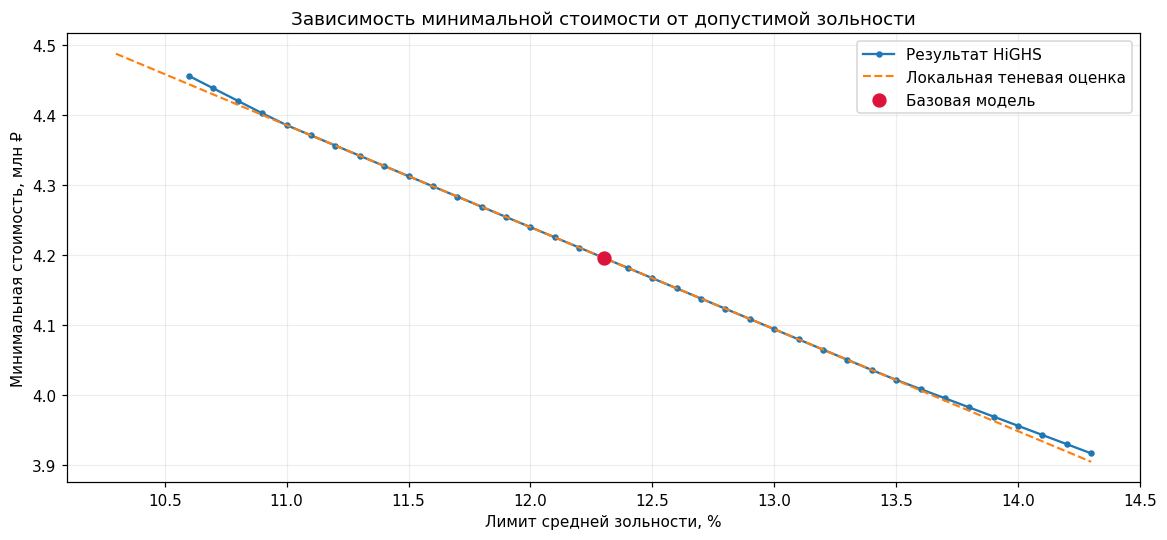

In [15]:
ash_grid = np.linspace(A_MAX - 2.0, A_MAX + 2.0, 41)
actual_costs = []
for a in ash_grid:
    rr = solve_mix(ash_limit=float(a))
    actual_costs.append(rr.fun / 1e6 if rr.success else np.nan)
predicted_costs = (base.fun + q_shadow[0] * D * (ash_grid - A_MAX)) / 1e6
fig, ax = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
ax.plot(ash_grid, actual_costs, marker='o', markersize=3.2, label='Результат HiGHS')
ax.plot(ash_grid, predicted_costs, '--', linewidth=1.4, label='Локальная теневая оценка')
ax.scatter([A_MAX], [base.fun / 1e6], s=70, color='crimson', zorder=5, label='Базовая модель')
ax.set(title='Зависимость минимальной стоимости от допустимой зольности',
       xlabel='Лимит средней зольности, %', ylabel='Минимальная стоимость, млн ₽')
ax.legend()
fig.savefig(OUTPUT_DIR / '05_sensitivity.png', bbox_inches='tight')
plt.show()

## 8. Итоговая интерпретация и практическая применимость

Здесь автоматически формируются выводы на основе рассчитанных данных, а не заранее вписанных чисел. Результаты относятся к **синтетическому учебному набору** с seed 10031, а не к реальным ценам на уголь.

In [16]:
base_active = [names[i] for i in range(5) if abs(base.x[i] - limits[i]) < 1e-7]
base_zero = [names[i] for i in range(5) if base.x[i] < 1e-7]
deficit_res = scenario_results['Дефицитный']
tight_res = scenario_results['Жёсткий допустимый']

conclusion = f"""**Базовый результат.** Оптимальная смесь массой {D:,.0f} т обходится в **{base.fun:,.2f} ₽** ({base.fun/D:,.2f} ₽/т). Средняя зольность — **{ash_base:.3f}%**, сера — **{sulfur_base:.3f}%**. Оба норматива качества активны.

**Ограниченность поставок.** Полностью загружены: **{', '.join(base_active) if base_active else 'нет'}**. Нулевые закупки: **{', '.join(base_zero) if base_zero else 'нет'}**. Все положительные закупки могут сосуществовать в оптимуме: даже сравнительно дорогой уголь позволяет разбавлять более загрязнённый дешёвый уголь.

**Дефицит.** Сокращение мощности поставщика № 2 на 20% приводит к стоимости **{deficit_res.fun:,.2f} ₽**, что на **{deficit_res.fun-base.fun:,.2f} ₽** больше базовой. Рост цены обусловлен необходимостью изменить состав смеси, сохранив экологические требования.

**Стресс.** Основной стрессовый сценарий имеет статус **{status_names[stress.status]}**. При одновременно заданных сокращениях отгрузки и сере ≤ 0,9% даже минимально достижимая зольность равна **{min_ash_achievable:.3f}%**, то есть выше допустимых 10,5%. Для восстановления допустимости придётся ослабить хотя бы одно условие или найти дополнительные поставки.

**Жёсткий, но выполнимый сценарий.** При нормативе зольности 11,3% и серы 1,0% стоимость составляет **{tight_res.fun:,.2f} ₽**, увеличение относительно базы — **{tight_res.fun-base.fun:,.2f} ₽**.

**Теневые цены.** Вблизи базового решения повышение допустимой зольности на 0,01 процентного пункта изменяет стоимость примерно на **{q_shadow[0]*D*0.01:,.2f} ₽**; повышение допустимой серы на 0,01 процентного пункта — на **{q_shadow[1]*D*0.01:,.2f} ₽**. Отрицательный знак означает экономию при ослаблении норматива.

**Проверка.** Все допустимые сценарии повторно проверены кодом NumPy с допуском 10⁻⁷; стоимость в базовом сценарии независимо пересчитана. Найденный план применим как агрегированный план закупки, но для реального ТЭС необходим учёт теплоты сгорания, влажности, логистики, условий контракта, качества партий и целочисленных ограничений перевозки."""
display(Markdown(conclusion))

**Базовый результат.** Оптимальная смесь массой 1,000 т обходится в **4,195,862.48 ₽** (4,195.86 ₽/т). Средняя зольность — **12.300%**, сера — **1.250%**. Оба норматива качества активны.

**Ограниченность поставок.** Полностью загружены: **Поставщик 2, Поставщик 3**. Нулевые закупки: **нет**. Все положительные закупки могут сосуществовать в оптимуме: даже сравнительно дорогой уголь позволяет разбавлять более загрязнённый дешёвый уголь.

**Дефицит.** Сокращение мощности поставщика № 2 на 20% приводит к стоимости **4,225,215.82 ₽**, что на **29,353.33 ₽** больше базовой. Рост цены обусловлен необходимостью изменить состав смеси, сохранив экологические требования.

**Стресс.** Основной стрессовый сценарий имеет статус **infeasible**. При одновременно заданных сокращениях отгрузки и сере ≤ 0,9% даже минимально достижимая зольность равна **11.707%**, то есть выше допустимых 10,5%. Для восстановления допустимости придётся ослабить хотя бы одно условие или найти дополнительные поставки.

**Жёсткий, но выполнимый сценарий.** При нормативе зольности 11,3% и серы 1,0% стоимость составляет **4,395,188.00 ₽**, увеличение относительно базы — **199,325.52 ₽**.

**Теневые цены.** Вблизи базового решения повышение допустимой зольности на 0,01 процентного пункта изменяет стоимость примерно на **-1,458.31 ₽**; повышение допустимой серы на 0,01 процентного пункта — на **-803.03 ₽**. Отрицательный знак означает экономию при ослаблении норматива.

**Проверка.** Все допустимые сценарии повторно проверены кодом NumPy с допуском 10⁻⁷; стоимость в базовом сценарии независимо пересчитана. Найденный план применим как агрегированный план закупки, но для реального ТЭС необходим учёт теплоты сгорания, влажности, логистики, условий контракта, качества партий и целочисленных ограничений перевозки.

## 9. Воспроизводимость и комплект выгружаемых файлов

Этот `.ipynb` является **единственным входным файлом**. После команды «Run All» он создаёт в папке `lab1_outputs/` данные, решение, сравнительные сценарии, визуализации, протокол решателя, отчёт и файлы для повторного запуска. Все необходимые таблицы и графики также сохраняются непосредственно в выводах ячеек блокнота.

In [17]:
import importlib.metadata

report = f"""# Лабораторная работа № 1. Вариант 14. Seed 10031

## Постановка
Смешение углей для ТЭС из пяти источников. Минимизируется стоимость закупки C = Σ cᵢxᵢ при Σxᵢ=1000 т, Σaᵢxᵢ≤12,3·1000, Σsᵢxᵢ≤1,25·1000 и 0≤xᵢ≤uᵢ. Зольность и сера заданы в процентах. Объёмы непрерывны.

## Происхождение данных
Учебные параметры с seed 10031 сгенерированы по правилам в блокноте; методичка не фиксирует численные исходные данные. Точные значения находятся в coal_data.json.

## Результаты
{base_solution.to_markdown(index=False, floatfmt='.3f')}

Стоимость: {base.fun:,.2f} ₽; зольность: {ash_base:.5f}%; сера: {sulfur_base:.5f}%.

## Проверка
Максимальное нарушение: {check['максимальное_нарушение']:.3e}; допустимо: {check['допустимо']}. Цена пересчитана отдельно: {check['стоимость_независимая']:,.2f} ₽.

## Сценарии
{scenario_df.to_markdown(index=False, floatfmt='.3f')}

## Теневые оценки
{economic_table.to_markdown(index=False, floatfmt='.3f')}

## Выводы
{conclusion.replace('**', '')}

## Допущения
Линейное смешивание по массе, фиксированные цены, однородное сырьё, непрерывность закупок. Не учитываются калорийность, влажность, транспорт, потери и сезонность.
"""
(OUTPUT_DIR / 'report.md').write_text(report, encoding='utf-8')

requirements = '\n'.join([
    f'numpy=={np.__version__}', f'pandas=={pd.__version__}',
    f'scipy=={scipy.__version__}', f'matplotlib=={matplotlib.__version__}',
    f'nbformat=={importlib.metadata.version("nbformat")}',
    f'ipykernel=={importlib.metadata.version("ipykernel")}',
    'tabulate==' + importlib.metadata.version('tabulate')
]) + '\n'
(OUTPUT_DIR / 'requirements.txt').write_text(requirements, encoding='utf-8')

readme = """# ЛР № 1 — вариант 14, seed 10031

Входной файл: Lab1_Variant14_seed10031.ipynb. Данные синтезируются детерминированно внутри блокнота.

Вариант воспроизведения:

```bash
python -m pip install -r lab1_outputs/requirements.txt
jupyter nbconvert --to notebook --execute Lab1_Variant14_seed10031.ipynb --output Lab1_Variant14_executed.ipynb
```

Первый запуск возможен в Jupyter через Kernel → Restart & Run All при установленных NumPy, pandas, SciPy, Matplotlib, ipykernel, tabulate.

Ожидаемые файлы: coal_data.json, solution.csv, scenarios.csv, solver.log, report.md, PNG-графики.

Все исходные данные синтетические; методичка не определяет диапазоны генерации.
"""
(OUTPUT_DIR / 'README.md').write_text(readme, encoding='utf-8')

log_lines = [f'ЛР1 | Вариант {VARIANT} | seed {SEED}', f'Python {platform.python_version()}',
             f'SciPy {scipy.__version__}; HiGHS через linprog, method=highs-ds, presolve=True',
             'Протокол статусов и числа итераций, формируемый интерфейсом SciPy (не нативный stdout HiGHS).', '']
for spec in scenario_specs:
    res = scenario_results[spec['Название']]
    log_lines.extend([f"Сценарий: {spec['Название']}", f'Status: {status_names.get(res.status, str(res.status))}',
                      f'Message: {res.message}', f'Iterations: {res.nit}',
                      f'Objective: {res.fun if res.success else "N/A"}', ''])
(OUTPUT_DIR / 'solver.log').write_text('\n'.join(log_lines), encoding='utf-8')

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name, '|', f'{file.stat().st_size:,} байт')

01_suppliers.png | 82,317 байт
02_optimal_mix.png | 103,904 байт
03_scenario_composition.png | 42,596 байт
04_scenario_comparison.png | 73,711 байт
05_sensitivity.png | 94,984 байт
README.md | 891 байт
coal_data.json | 1,026 байт
report.md | 7,206 байт
requirements.txt | 111 байт
scenarios.csv | 425 байт
solution.csv | 530 байт
solver.log | 1,003 байт
